In [82]:
%pip install yfinance

Note: you may need to restart the kernel to use updated packages.


In [83]:
import pandas as pd 
import matplotlib.pyplot as plt
import yfinance as yf
import numpy as np


In [84]:
basket = ['AAPL', 'MSFT', 'NVDA', 'AMZN', 'GOOGL', 'META']

In [85]:
data = yf.download(
    basket,
    start='2010-01-01',
    auto_adjust=False,
    actions=True
)

prices = data['Close'][basket].dropna()

splits = data['Stock Splits'][basket].reindex(prices.index).fillna(0)

split_factors = splits.replace(0, 1).iloc[1:].prod()


tech_etf = prices.mul(split_factors, axis=1).sum(axis=1).to_frame(name='Price')

[*********************100%***********************]  6 of 6 completed


Text(0, 0.5, 'Combined Stock Price (USD)')

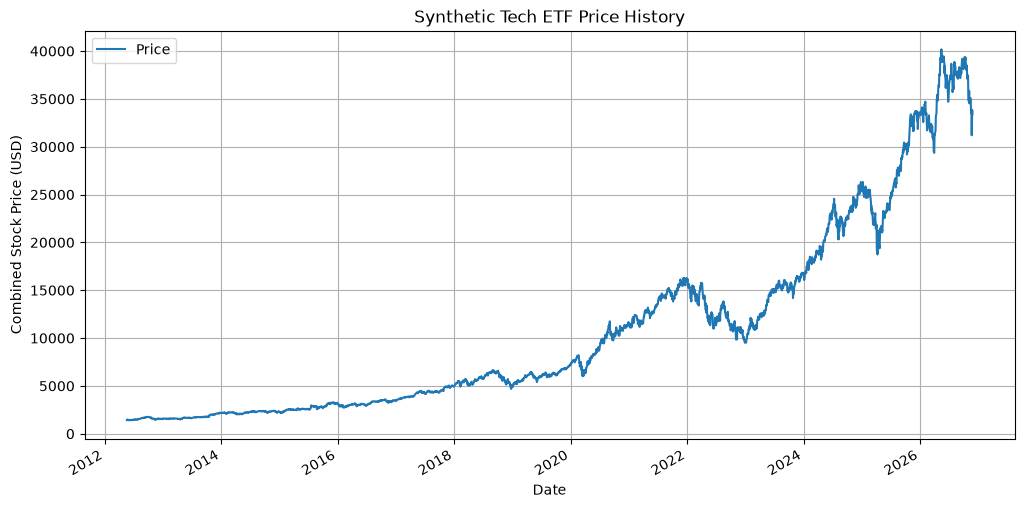

In [86]:

ax = tech_etf.plot(
    title='Synthetic Tech ETF Price History',
    figsize=(12, 6),
    grid=True
)

ax.set_xlabel('Date')
ax.set_ylabel('Combined Stock Price (USD)')

Now we will look at the relationships between the rolling averages over some general time amount.

two hundered just gives us some general baseline whereas the twenty, ten and five can give us some general "momentum" figure that we might be able to exploit.

In [87]:
tech_etf['MA_5'] = tech_etf['Price'].rolling(5).mean()
tech_etf['MA_10'] = tech_etf['Price'].rolling(10).mean()
tech_etf['MA_20'] = tech_etf['Price'].rolling(20).mean()
tech_etf['MA_200'] = tech_etf['Price'].rolling(200).mean()
tech_etf['5_20_MA_Diff'] = tech_etf['MA_5'] - tech_etf['MA_20']

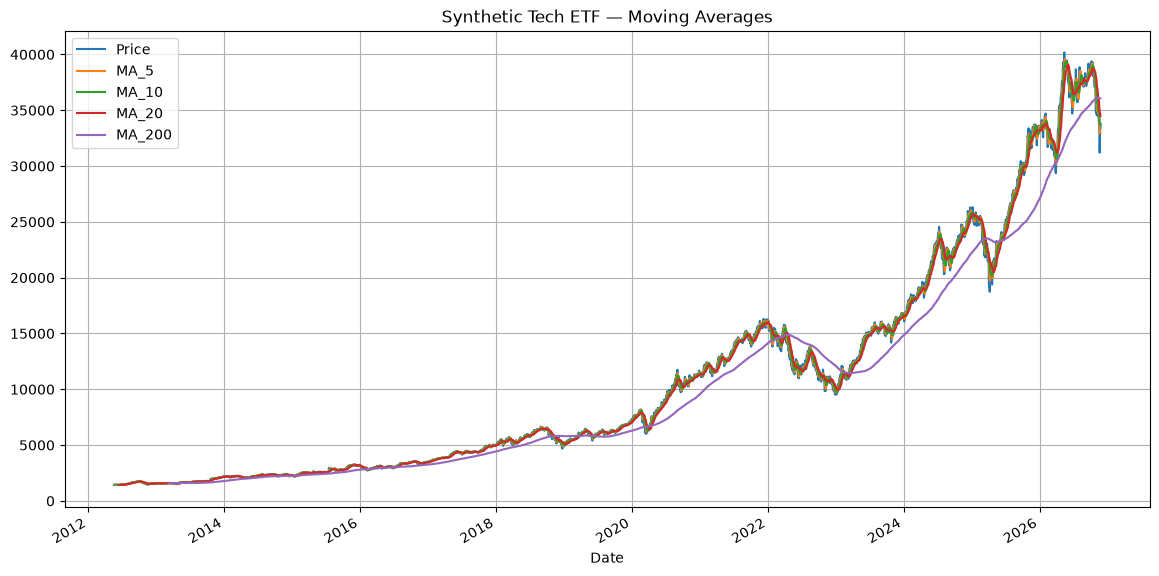

In [88]:
tech_etf[['Price', 'MA_5', 'MA_10', 'MA_20', 'MA_200']].plot(
    figsize=(14, 7),
    title='Synthetic Tech ETF — Moving Averages',
    grid=True
)

plt.show()

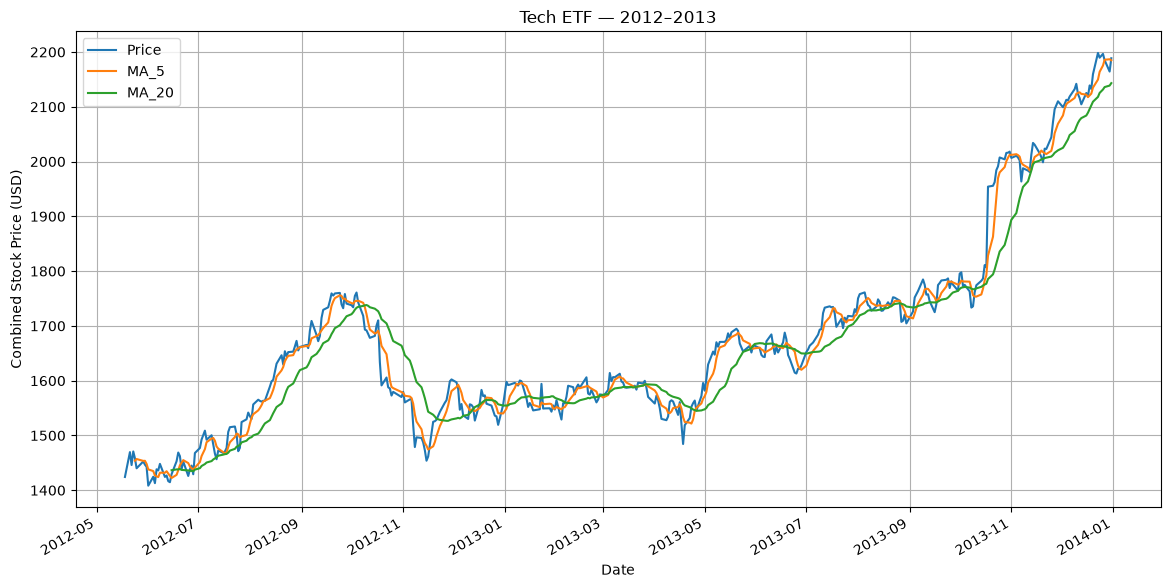

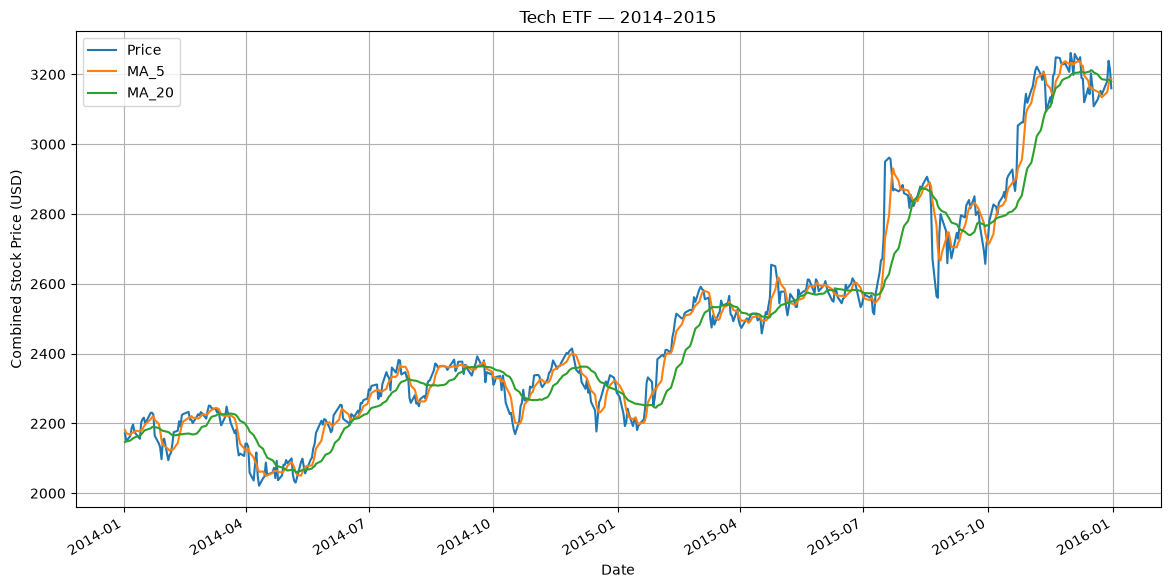

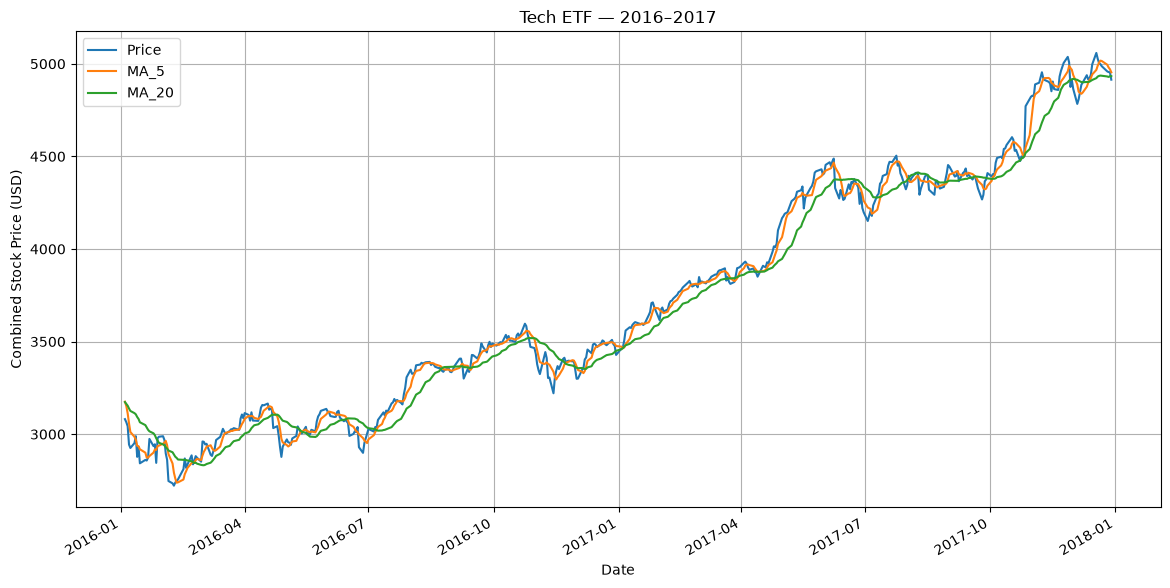

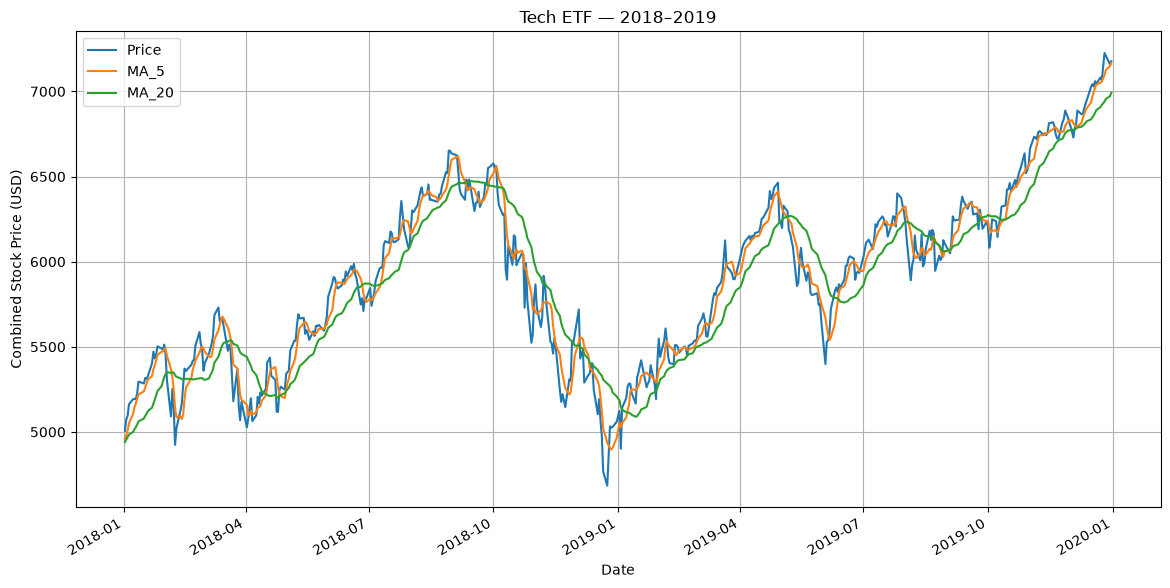

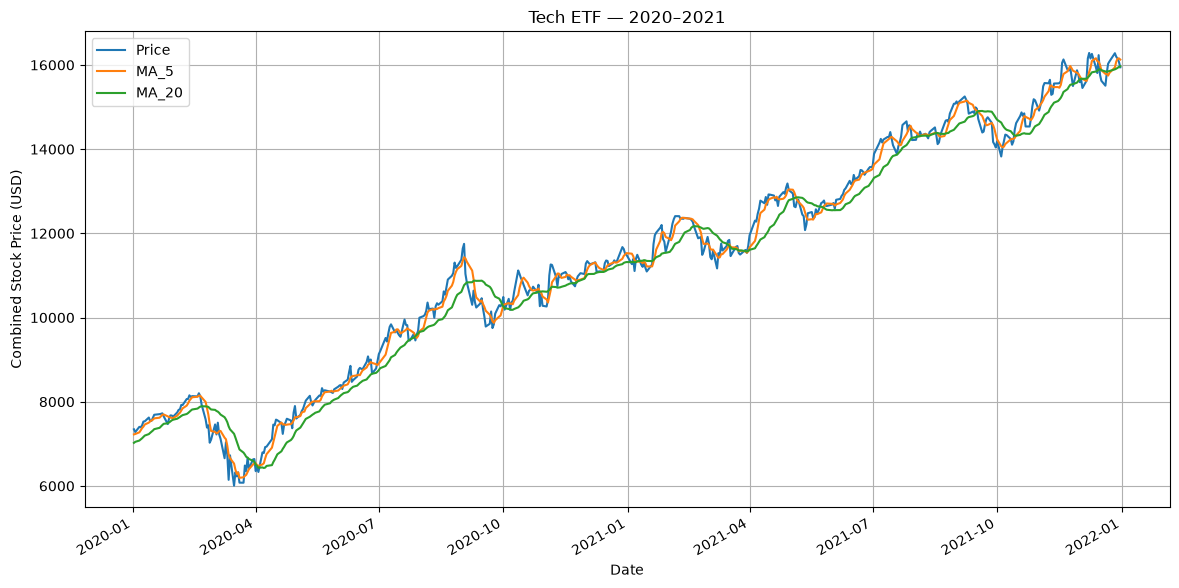

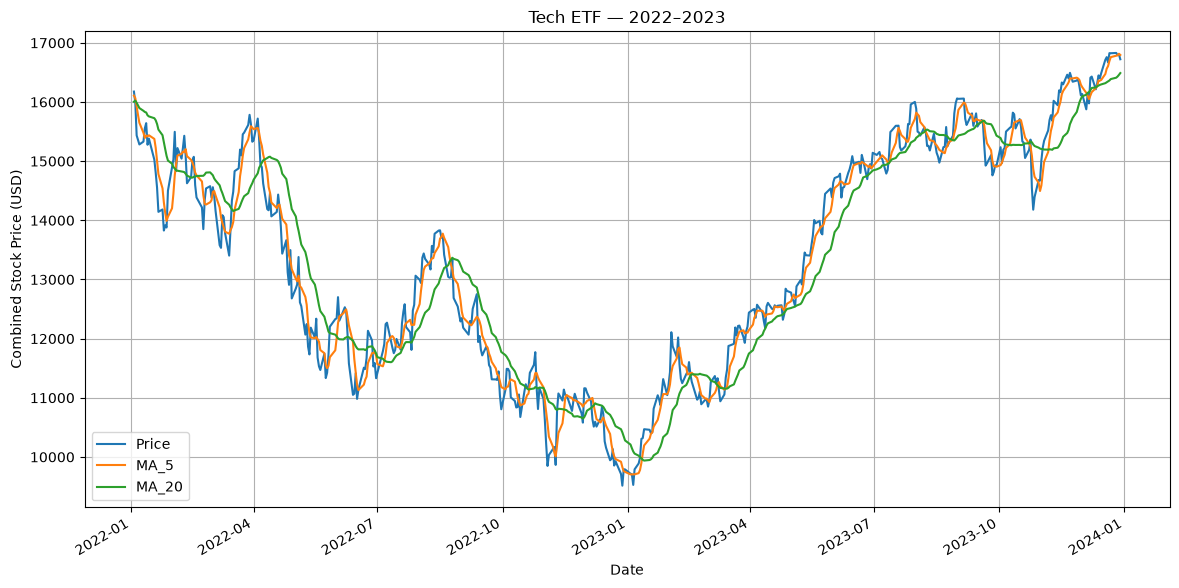

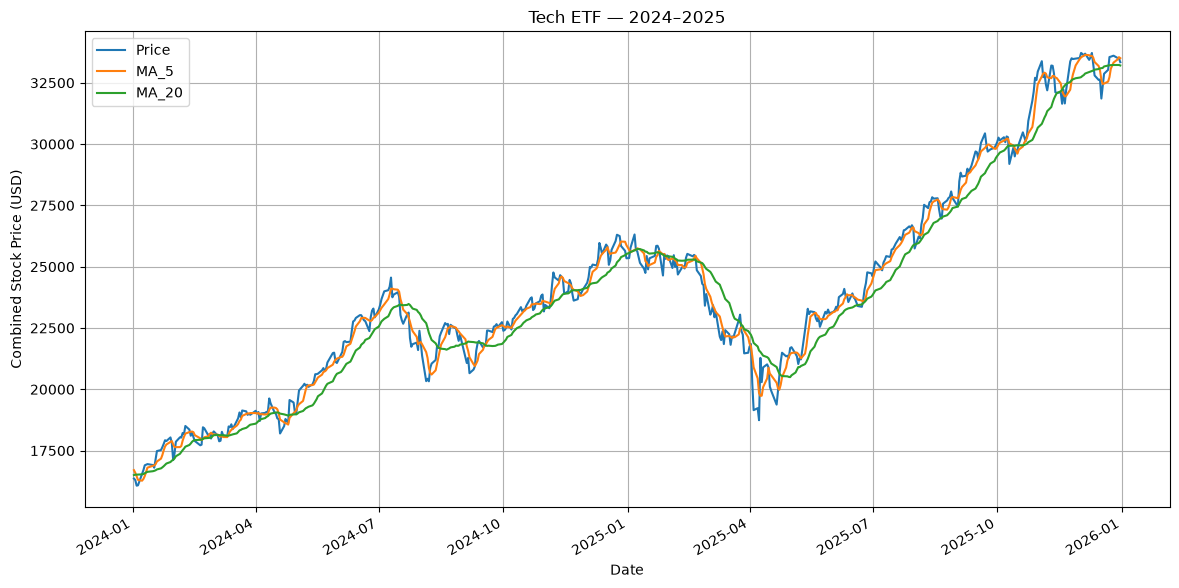

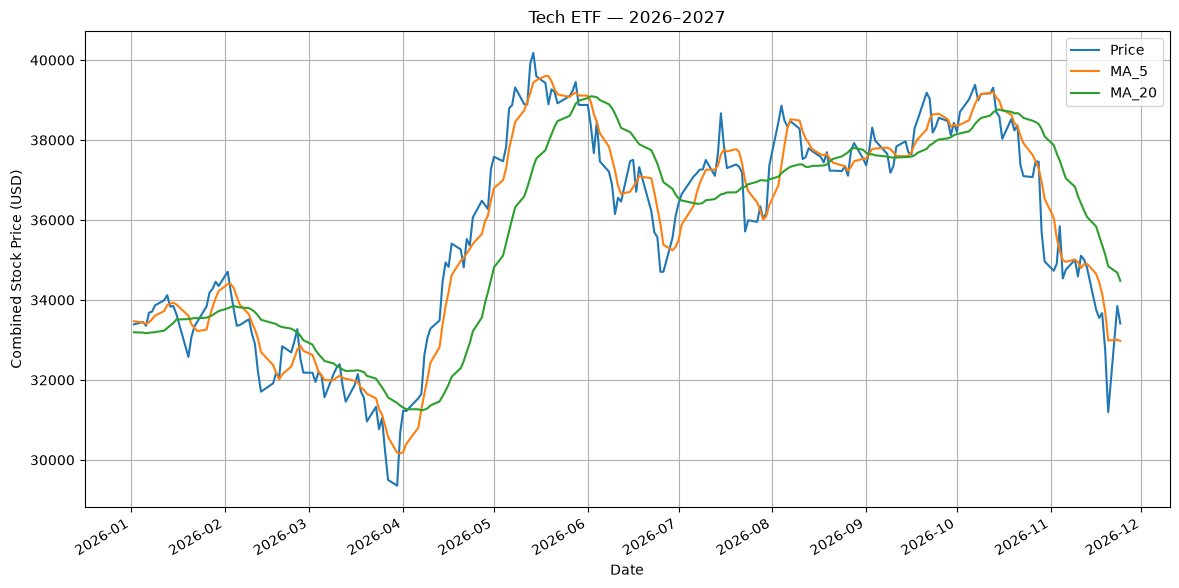

In [89]:
import matplotlib.pyplot as plt

start_year = tech_etf.index.min().year
end_year = tech_etf.index.max().year

for year in range(start_year, end_year + 1, 2):

    period = tech_etf.loc[str(year):str(year + 1)]

    if period.empty:
        continue

    period[['Price', 'MA_5', 'MA_20']].plot(
        figsize=(14, 7),
        title=f'Tech ETF — {year}–{year + 1}',
        grid=True
    )

    plt.ylabel('Combined Stock Price (USD)')
    plt.xlabel('Date')
    plt.show()

We will start with a simple strategy: buy when 5-day MA crosses above the 20-day MA. Sell when the 5-day MA crosses below the 20-day MA. Otherwise maintain. $D_t = SMA_{5}(t) - SMA_{20}(t)$, a buy occurs when $D_{t-1} \leq 0$ and $D_t > 0$ and a sell occurs when $D_{t-1} \geq 0$ and $D_t < 0$. 

In [90]:
tech_etf = tech_etf.dropna(subset=['MA_5', 'MA_20']).copy()

tech_etf['5_20_MA_Diff'] = tech_etf['MA_5'] - tech_etf['MA_20']


tech_etf['Trend'] = (
    tech_etf['MA_5'] > tech_etf['MA_20']
).astype(int)


tech_etf['Trend_Change'] = (
    tech_etf['Trend'] - tech_etf['Trend'].shift(1)
)

In [91]:
initial_capital = 10_000


tech_etf['Daily_Return'] = tech_etf['Price'].pct_change().fillna(0)


tech_etf['Position'] = tech_etf['Trend'].shift(2).fillna(0).astype(int)


tech_etf['Trade'] = tech_etf['Position'].diff().abs().fillna(0)


cost_rate = 0.001 


tech_etf['Strategy_Return'] = (
    (1 + tech_etf['Position'] * tech_etf['Daily_Return'])
    * (1 - cost_rate * tech_etf['Trade'])
    - 1
)


tech_etf['Strategy_Value'] = (
    initial_capital * (1 + tech_etf['Strategy_Return']).cumprod()
)


tech_etf['Buy_Hold_Value'] = (
    initial_capital * tech_etf['Price'] / tech_etf['Price'].iloc[0]
)

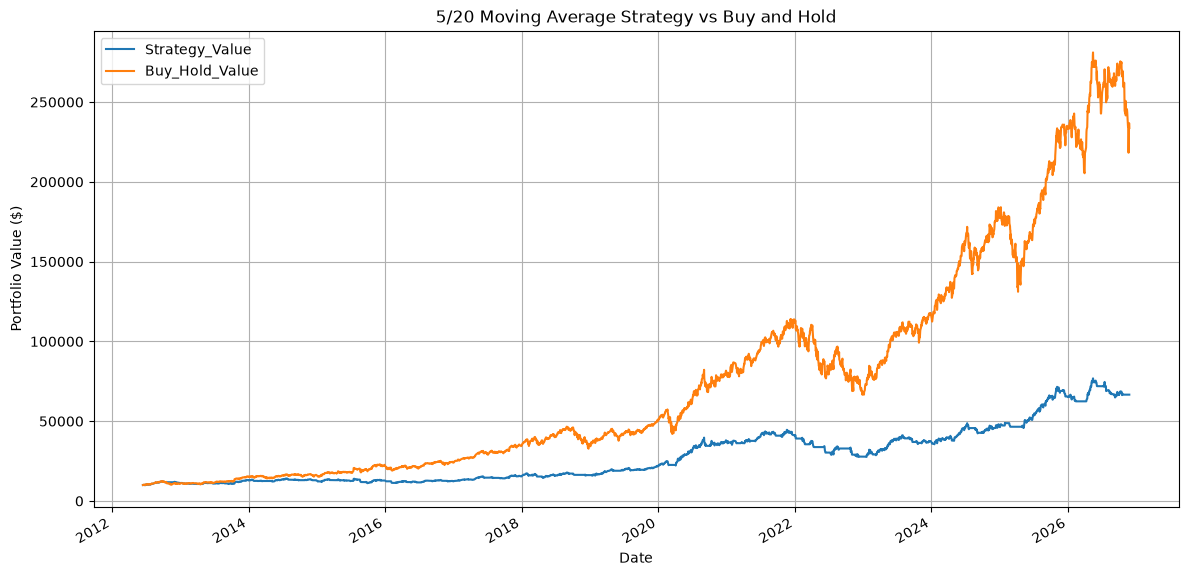

In [92]:
tech_etf[['Strategy_Value', 'Buy_Hold_Value']].plot(
    figsize=(14, 7),
    title='5/20 Moving Average Strategy vs Buy and Hold',
    grid=True
)

plt.xlabel('Date')
plt.ylabel('Portfolio Value ($)')
plt.show()

In [93]:
strategy_return = (
    tech_etf['Strategy_Value'].iloc[-1] / initial_capital - 1
)

buy_hold_return = (
    tech_etf['Buy_Hold_Value'].iloc[-1] / initial_capital - 1
)

number_of_trades = int(tech_etf['Trade'].sum())

print(f"Strategy Total Return: {strategy_return:.2%}")
print(f"Buy & Hold Total Return: {buy_hold_return:.2%}")
print(f"Number of Trades: {number_of_trades}")

Strategy Total Return: 566.38%
Buy & Hold Total Return: 2237.61%
Number of Trades: 214


## Backtest audit — next-close execution

A crossover becomes known at the close of session $t$. Under the next-close convention, the position changes at the close of $t+1$, after the previous position earns that session's return. The new position first earns the close-to-close return ending on $t+2$. The original `Position` already follows this timing. The comparison below books the 0.1% fee at the execution close.

In [94]:
position_at_close = tech_etf['Trend'].shift(1, fill_value=0)
trade_at_close = position_at_close.diff().abs().fillna(0)

gross_growth = 1 + tech_etf['Position'] * tech_etf['Daily_Return']
net_growth_at_close = gross_growth * (1 - cost_rate * trade_at_close)
strategy_value_at_close = initial_capital * net_growth_at_close.cumprod()

print(f"Sample ends {tech_etf.index[-1]:%Y-%m-%d}")
print(f"Sessions with different fee booking: {(tech_etf['Trade'] != trade_at_close).sum()}")

pd.DataFrame(
    {
        'Total return (%)': [
            100 * strategy_return,
            100 * (strategy_value_at_close.iloc[-1] / initial_capital - 1),
        ],
        'Position changes': [number_of_trades, int(trade_at_close.sum())],
    },
    index=['Original notebook', 'Fee at execution close'],
).round(2)

Sample ends 2026-11-24
Sessions with different fee booking: 392


,Total return (%),Position changes
Original notebook,566.38,214
Fee at execution close,566.38,214


## Risk and exposure

Both portfolios use the same sample. The strategy uses fees booked at the execution close. CAGR uses elapsed calendar years. Volatility and Sharpe use 252 sessions per year and a zero risk-free rate. The opening row sets starting wealth, so daily statistics begin on the second row.

In [95]:
strategy_label = '5/20 strategy (net)'
benchmark_label = 'Buy and hold'

daily_returns = pd.DataFrame({
    strategy_label: net_growth_at_close - 1,
    benchmark_label: tech_etf['Daily_Return'],
}).iloc[1:]
equity = pd.DataFrame({
    strategy_label: strategy_value_at_close,
    benchmark_label: tech_etf['Buy_Hold_Value'],
})

is_invested = tech_etf.loc[daily_returns.index, 'Position'].eq(1)
drawdowns = equity / equity.cummax() - 1
elapsed_years = (equity.index[-1] - equity.index[0]).days / 365.25
annual_volatility = daily_returns.std() * np.sqrt(252)

risk_metrics = pd.DataFrame({
    'Market exposure (%)': [100 * is_invested.mean(), 100.0],
    'CAGR (%)': 100 * ((equity.iloc[-1] / equity.iloc[0]) ** (1 / elapsed_years) - 1),
    'Annualised volatility (%)': 100 * annual_volatility,
    'Sharpe ratio': 252 * daily_returns.mean() / annual_volatility,
    'Maximum drawdown (%)': 100 * drawdowns.min(),
}, index=equity.columns)

print(f"Sample: {equity.index[0]:%Y-%m-%d} to {equity.index[-1]:%Y-%m-%d}")
risk_metrics.round(2)

Sample: 2012-06-15 to 2026-11-24


,Market exposure (%),CAGR (%),Annualised volatility (%),Sharpe ratio,Maximum drawdown (%)
5/20 strategy (net),65.79,14.03,16.65,0.87,-38.10
Buy and hold,100.00,24.39,24.65,1.01,-41.58


## Drawdowns

A drawdown measures the percentage decline from each portfolio's own previous high. The dots mark the deepest drawdowns.

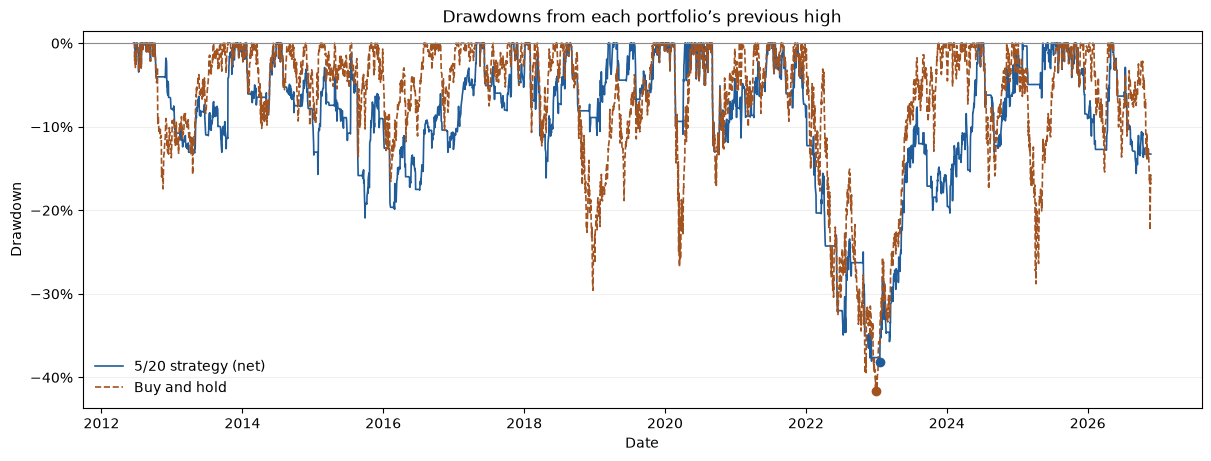

In [96]:
from matplotlib.ticker import PercentFormatter

fig, ax = plt.subplots(figsize=(12, 4.5), layout='constrained')
series_styles = [(strategy_label, '#1F5C99', '-'), (benchmark_label, '#A35320', '--')]

for portfolio, color, line_style in series_styles:
    drawdown = drawdowns[portfolio]
    trough_date = drawdown.idxmin()
    ax.plot(drawdown.index, drawdown, label=portfolio, color=color,
            linestyle=line_style, linewidth=1.2)
    ax.scatter(trough_date, drawdown.loc[trough_date], color=color, zorder=3)

ax.axhline(0, color='#8A8A8A', linewidth=0.8)
ax.set(title='Drawdowns from each portfolio’s previous high',
       xlabel='Date', ylabel='Drawdown', ylim=(None, 0.015))
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.grid(axis='y', alpha=0.2)
ax.legend(loc='lower left', frameon=False)
plt.show()

## What happened while the strategy held cash?

The table groups the basket's daily returns by the position held over each close-to-close interval. The compounded return in the cash row combines only those intervals. It reflects gains missed and losses avoided. The second table shows the most positive and most negative consecutive cash spells, with dates marking the closes that end the return intervals.

In [97]:
basket_returns = daily_returns[benchmark_label]
cash_returns = basket_returns.loc[~is_invested]
position_names = is_invested.map({True: 'Invested', False: 'In cash'})

returns_by_position = basket_returns.groupby(position_names).agg(**{
    'Sessions': 'size',
    'Up sessions (%)': lambda returns: 100 * returns.gt(0).mean(),
    'Mean daily return (%)': lambda returns: 100 * returns.mean(),
    'Compounded return (%)': lambda returns: 100 * ((1 + returns).prod() - 1),
}).rename_axis('Strategy position')
display(returns_by_position.round({
    'Up sessions (%)': 2,
    'Mean daily return (%)': 3,
    'Compounded return (%)': 2,
}))

cash_spell_id = is_invested.ne(is_invested.shift()).cumsum()
cash_spells = (
    cash_returns.to_frame('Return')
    .assign(Date=cash_returns.index)
    .groupby(cash_spell_id)
    .agg(**{
        'First return date': ('Date', 'min'),
        'Last return date': ('Date', 'max'),
        'Sessions': ('Return', 'size'),
        'Basket return (%)': ('Return', lambda returns: 100 * ((1 + returns).prod() - 1)),
    })
)

spell_return = 'Basket return (%)'
extreme_cash_spells = pd.concat([
    cash_spells.nlargest(3, spell_return),
    cash_spells.nsmallest(3, spell_return),
]).drop_duplicates()
extreme_cash_spells[spell_return] = extreme_cash_spells[spell_return].round(2)
extreme_cash_spells.reset_index(drop=True)

,Sessions,Up sessions (%),Mean daily return (%),Compounded return (%)
Strategy position,,,,
In cash,1242,56.52,0.103,183.18
Invested,2389,54.83,0.097,725.48


,First return date,Last return date,Sessions,Basket return (%)
0,2022-06-15,2022-07-08,16,10.84
1,2015-08-25,2015-09-15,15,10.15
2,2022-11-03,2022-11-17,11,7.93
3,2018-10-10,2018-12-04,39,-13.54
4,2020-02-27,2020-04-02,26,-13.54
5,2022-08-26,2022-10-24,41,-13.30


## Trading costs and the return gap

The gross and net strategies take identical positions. The net strategy pays 0.1% per position change. Buy and hold has zero modeled trading fees. Dividing buy-and-hold ending wealth by net strategy ending wealth gives the product of two factors. The first is the basket's compounded growth during cash intervals. The second is the inverse of the fee multiplier. Taking logs makes those two contributions additive.

In [98]:
gross_value = initial_capital * gross_growth.cumprod()
terminal_values = pd.Series({
    '5/20 strategy (gross)': gross_value.iloc[-1],
    strategy_label: equity[strategy_label].iloc[-1],
    benchmark_label: equity[benchmark_label].iloc[-1],
})

cost_comparison = pd.DataFrame({
    'Ending wealth ($)': terminal_values,
    'Total return (%)': 100 * (terminal_values / initial_capital - 1),
})
display(cost_comparison.round(2))

cash_growth = (1 + cash_returns).prod()
fee_multiplier = (1 - cost_rate * trade_at_close).prod()
wealth_gap_factors = pd.Series({
    'Basket growth during cash intervals': cash_growth,
    'Inverse of fee multiplier': 1 / fee_multiplier,
})
wealth_ratio = terminal_values[benchmark_label] / terminal_values[strategy_label]
assert np.isclose(wealth_gap_factors.prod(), wealth_ratio)

wealth_gap = pd.DataFrame({
    'Wealth ratio factor': wealth_gap_factors,
    'Contribution to log wealth gap': np.log(wealth_gap_factors),
})
wealth_gap.round(4)

,Ending wealth ($),Total return (%)
5/20 strategy (gross),82547.89,725.48
5/20 strategy (net),66637.77,566.38
Buy and hold,233761.38,2237.61


,Wealth ratio factor,Contribution to log wealth gap
Basket growth during cash intervals,2.8318,1.0409
Inverse of fee multiplier,1.2388,0.2141


## Do crossovers forecast basket returns?

A bullish event is a transition from cash to long in the signal. A bearish event is the reverse. For a signal known at close $t$, measure the basket return from that close to $t+h$, for $h$ of 1, 5, 10 and 20 trading sessions. This measures the forecast from the signal time. The backtest trades at the next close.

For each horizon, compare the mean after each crossover with the mean across all dates with both today's and the previous day's signal available and a complete forward window. Also show the median and the fraction of positive returns after each event. The 95% intervals are for the mean difference in percentage points. The [circular block bootstrap](https://statistics.stanford.edu/technical-reports/circular-block-resampling-procedure-stationary-data) resamples 40-session blocks of dates to retain some dependence from overlapping returns. These are exploratory, in-sample intervals for individual comparisons.

In [99]:
def bootstrap_mean_gaps(returns, changes, block_size=40, draws=2_000):
    """Estimate the bullish and bearish mean gaps on resampled trading dates."""
    rng = np.random.default_rng(42)
    gaps = {1: [], -1: []}
    n_dates = len(returns)
    offsets = np.arange(block_size)
    n_blocks = (n_dates + block_size - 1) // block_size

    if n_dates >= 2 * block_size:
        for _ in range(draws):
            starts = rng.integers(n_dates, size=n_blocks)
            indices = ((starts[:, None] + offsets) % n_dates).ravel()[:n_dates]
            sampled_returns = returns[indices]
            sampled_changes = changes[indices]
            baseline_mean = sampled_returns.mean()
            for change, estimates in gaps.items():
                event_returns = sampled_returns[sampled_changes == change]
                if len(event_returns):
                    estimates.append(event_returns.mean() - baseline_mean)

    return {
        change: np.quantile(estimates, [0.025, 0.975]) if len(estimates) > 1
        else (np.nan, np.nan)
        for change, estimates in gaps.items()
    }


price = tech_etf['Price']
event_rows = []
for horizon in [1, 5, 10, 20]:
    forward_returns = pd.DataFrame({
        'Return': price.shift(-horizon) / price - 1,
        'Change': tech_etf['Trend_Change'],
    }).dropna()

    baseline_mean = forward_returns['Return'].mean()
    intervals = bootstrap_mean_gaps(
        forward_returns['Return'].to_numpy(),
        forward_returns['Change'].to_numpy(),
    )

    for change, direction in [(1, 'Bullish'), (-1, 'Bearish')]:
        event_returns = forward_returns.loc[forward_returns['Change'].eq(change), 'Return']
        lower, upper = intervals[change]
        event_rows.append({
            'Horizon (sessions)': horizon,
            'Crossover': direction,
            'Events': len(event_returns),
            'Mean (%)': 100 * event_returns.mean(),
            'Median (%)': 100 * event_returns.median(),
            'Positive (%)': 100 * event_returns.gt(0).mean(),
            'All-date mean (%)': 100 * baseline_mean,
            'Mean gap (pp)': 100 * (event_returns.mean() - baseline_mean),
            '95% lower (pp)': 100 * lower,
            '95% upper (pp)': 100 * upper,
        })

crossover_results = pd.DataFrame(event_rows).set_index(['Horizon (sessions)', 'Crossover'])
crossover_results.round(2)

Events  Mean (%)  Median (%)  Positive (%)  \
Horizon (sessions) Crossover                                               
1                  Bullish       107     -0.06        0.05         51.40   
                   Bearish       107     -0.01        0.10         51.40   
5                  Bullish       107      0.47        0.67         56.07   
                   Bearish       107      0.48        0.36         56.07   
10                 Bullish       107      0.84        1.09         62.62   
                   Bearish       107      0.94        1.11         58.88   
20                 Bullish       107      2.20        2.21         67.29   
                   Bearish       107      1.74        1.85         62.62   

                              All-date mean (%)  Mean gap (pp)  \
Horizon (sessions) Crossover                                     
1                  Bullish                 0.10          -0.16   
                   Bearish                 0.10          -0.11   
5                  Bullish                 0.48          -0.01   
                   Bearish                 0.48          -0.00   
10                 Bullish                 0.97          -0.13   
                   Bearish                 0.97          -0.03   
20                 Bullish                 1.96           0.24   
                   Bearish                 1.96          -0.22   

                              95% lower (pp)  95% upper (pp)  
Horizon (sessions) Crossover                                  
1                  Bullish             -0.42            0.10  
                   Bearish             -0.36            0.13  
5                  Bullish             -0.63            0.62  
                   Bearish             -0.55            0.52  
10                 Bullish             -0.88            0.66  
                   Bearish             -0.82            0.68  
20                 Bullish             -0.78            1.32  
                   Bearish             -1.18            0.77

## Findings through 24 November 2026

- The strategy was invested for 65.79% of return intervals. It reduced annualised volatility from 24.65% to 16.65%, but maximum drawdown was still 38.10% and the Sharpe ratio fell from 1.01 to 0.87.
- The basket gained 183.18% across the cash intervals. Those returns account for about 83% of the log ending-wealth gap. Fees account for the remainder under the backtest assumptions.
- All eight crossover intervals include a zero mean gap versus the all-date baseline. The historical event study shows no clear forecasting edge at the tested horizons.